In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

os.listdir("/content/drive/MyDrive/PROJECT_DM")

['Social_Network_Data_and_Practices_The_Case_of_Frie.pdf',
 'handle_data.ipynb',
 'entries_cleaned.csv',
 'comments_cleaned.csv',
 'likes_cleaned.csv',
 'users_cleaned.csv',
 'following_cleaned.csv',
 'entries_with_language.csv',
 'Project_DM.gdoc',
 'Presentation DM.gslides',
 'FINAL_PRESENTATION.gslides']

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans


In [ ]:
entry_columns = [
    "EntryID",
    "PostedBy",
    "SourceName",
    "SourceURL",
    "Text",
    "NumImg",
    "ImgURL",
    "NumVideo",
    "VideoURL",
    "Language"
]

comment_columns = [
    "CommentID",
    "EntryID",
    "PostedBy",
    "SourceName",
    "SourceURL",
    "Text",
]

likes_columns = [
    "UserID",
    "EntryID",
]

In [ ]:
folder = "/content/drive/MyDrive/PROJECT_DM/"

entries = pd.read_csv(
    folder + "entries_with_language.csv",
    sep="\t",
    header=None,
    names=entry_columns,
    na_values=r"\N"
)

comments = pd.read_csv(
    folder + "comments_cleaned.csv",
    sep="\t",
    header=None,
    names=comment_columns,
    na_values=r"\N"
)

likes = pd.read_csv(
    folder + "likes_cleaned.csv",
    sep="\t",
    header=None,
    names=likes_columns,
    na_values=r"\N"
)

In [ ]:
print("Entries:", entries.shape)
print("Comments:", comments.shape)
print("Likes:", likes.shape)

display(entries.head())
display(comments.head())
display(likes.head())

Entries: (11043310, 10)
Comments: (2675666, 6)
Likes: (446605, 2)


,EntryID,PostedBy,SourceName,SourceURL,Text,NumImg,ImgURL,NumVideo,VideoURL,Language
0,e/29af803d670fb8d67692095f3ee623e6,newsroom1,Ottawa Citizen - News,http://www.ottawacitizen.com/index.html,RIM 'will not compromise' BlackBerry security ...,1.0,http://www.ottawacitizen.com/will+compromise+...,0.0,NaN,en
1,e/9c8413a376bec6389be4d46d0812c2bb,mehmetinnet,Mehmetin.Net,http://www.mehmetin.net,Fethullah Gülen: Referandum siyasî olarak görü...,1.0,http://www.mehmetin.net/2010/08/fethullah-gul...,0.0,NaN,tr
2,e/2d658d97842a466a9513f587f85b0e59,mehmetergin,Mehmetin.Net,http://www.mehmetin.net/,Fethullah Gülen: Referandum siyasî olarak görü...,1.0,http://www.mehmetin.net/2010/08/fethullah-gul...,0.0,NaN,tr
3,e/b269ab5d56be4e5e90c1954ecc1ef63a,afriki,NaN,NaN,Мне тут недавно один дизайнер сказал: «Ну прот...,0.0,NaN,0.0,NaN,ru
4,e/74f0a50c374a4ad6bddcbcc60c60cad9,hamsafar,NaN,NaN,عرض سلام و خسته نباشيد:),0.0,NaN,0.0,NaN,fa


,CommentID,EntryID,PostedBy,SourceName,SourceURL,Text
0,e/ed12adf025b5491da54c4ff2c8c5377a/c/c2dbc8151...,e/ed12adf025b5491da54c4ff2c8c5377a,koenigdublin,NaN,NaN,В начале 20 века было противостояние идеологи...
1,e/624ca9226b6526ebdb69f9b46df482c7/c/32c6bf5bc...,e/624ca9226b6526ebdb69f9b46df482c7,guardianuk,NaN,NaN,Reel Review video: Catherine Shoard defends Kn...
2,e/2fdf59e075094fe1847137af34eda0f7/c/eb22afe81...,e/2fdf59e075094fe1847137af34eda0f7,nahi,m.ctor.org,http://m.ctor.org/f2p/,VMWareじゃなくてVMwareね。
3,e/4d8de05f989d43a4b90bfbfc59751e1c/c/d472f7b81...,e/4d8de05f989d43a4b90bfbfc59751e1c,miocaro,NaN,NaN,Anıl havuzdan uzak dur. Sen evde olacaksın :)
4,e/967b4db48fa74021b24ccbc93c55a61c/c/57905e983...,e/967b4db48fa74021b24ccbc93c55a61c,massoptimization,Bookmarklet,http://friendfeed.com/share/bookmarklet,Article by at 2010-08-06 09:42:14 Categoriz...


,UserID,EntryID
0,yasinde,e/2d4fcaed2d2a4ac1a36571b66da3f16c
1,socialnewsturkey,e/2d4fcaed2d2a4ac1a36571b66da3f16c
2,janzu,e/2d4fcaed2d2a4ac1a36571b66da3f16c
3,mugecerman,e/2d4fcaed2d2a4ac1a36571b66da3f16c
4,miocaro,e/2d4fcaed2d2a4ac1a36571b66da3f16c


In [ ]:
entries_en = entries[
    (entries["Language"] == "en") &
    (entries["Text"].notna())
].copy()

print("All entries:", len(entries))
print("English entries with text:", len(entries_en))

print(
    f"Percentage remaining: "
    f"{len(entries_en) / len(entries) * 100:.2f}%"
)

All entries: 11043310
English entries with text: 7489241
Percentage remaining: 67.82%


In [ ]:
like_count = (
    likes
    .groupby("EntryID")
    .size()
    .rename("NumLikes")
    .reset_index()
)

display(like_count.head())

,EntryID,NumLikes
0,e/00002649bfb04cd7854072733aa19f68,1
1,e/0000eb9390f045fa91c5a6cf7a29ce49,1
2,e/00012800d7e448e980d6b3ceedef2a5c,1
3,e/00012d8e9f7c4883a9af9618e7f43289,1
4,e/00013cf8df1343d9be7962afb6df9c57,1


In [ ]:
comment_count = (
    comments
    .groupby("EntryID")
    .size()
    .rename("NumComments")
    .reset_index()
)

display(comment_count.head())

,EntryID,NumComments
0,e/00000287090d42faab6b0c9c10931532,1
1,e/00001b664bc5ed8e0908e2aaf74da17b,1
2,e/00001e252ca2cf4b2dc60869eb4db6fc,1
3,e/00002649bfb04cd7854072733aa19f68,2
4,e/00005b86385c69d2c2bd2655758a6928,1


In [ ]:
entries_en = entries_en.merge(
    like_count,
    on="EntryID",
    how="left"
)

entries_en = entries_en.merge(
    comment_count,
    on="EntryID",
    how="left"
)

In [ ]:
entries_en["NumLikes"] = (
    entries_en["NumLikes"]
    .fillna(0)
    .astype(int)
)

entries_en["NumComments"] = (
    entries_en["NumComments"]
    .fillna(0)
    .astype(int)
)

In [ ]:
entries_en["Attention"] = (
    entries_en["NumLikes"] +
    entries_en["NumComments"]
)

In [ ]:
display(
    entries_en[
        [
            "EntryID",
            "Text",
            "NumLikes",
            "NumComments",
            "Attention"
        ]
    ].head(20)
)

,EntryID,Text,NumLikes,NumComments,Attention
0,e/29af803d670fb8d67692095f3ee623e6,RIM 'will not compromise' BlackBerry security ...,0,1,1
1,e/38867ca7a6b80722345569a30c1cf2d4,"A volte succede - <a rel=""nofollow"" href=""http...",0,5,5
2,e/36cfd2743b8a4385a374f79fcac358dd,Undersea river discovered flowing on sea bed -...,1,1,2
3,e/7dd779c201dbe9a9d2a97302cbf3640b,"The Ministry of Silly Walks - <a rel=""nofollow...",1,0,1
4,e/e1f39199b774a2f6f30e1caa4153061c,Lady Gaga - Bad Romance - live cover - Lissie ...,1,1,2
5,e/a7a6ccf5af844be5ac27d46c860e161c,CONFERENCE CALL TIME!,0,7,7
6,e/e38034a7d795d0308a7deed2cf490f60,"War In Iraq Nears Its End, Afghanistan Still A...",0,0,0
7,e/00ff96dad6ca2b47afda34f99b26d5de,"War In Iraq Nears Its End, Afghanistan Still A...",0,0,0
8,e/92e63f49a395e31d08cedf2486ba8254,On my way to Tel Aviv,0,0,0
9,e/788af85850d548f072b1a06e1b58b2dc,"Almost 100% Of Lawmakers Request Earmarks, Say...",0,1,1


In [ ]:
before = len(entries_en)

entries_en = entries_en[
    entries_en["Attention"] > 0
].copy()

after = len(entries_en)

print("Before filtering:", before)
print("After filtering:", after)
print("Removed:", before - after)

Before filtering: 7489241
After filtering: 726654
Removed: 6762587


In [ ]:
print("Minimum attention:", entries_en["Attention"].min())
print("Number of entries remaining:", len(entries_en))

Minimum attention: 1
Number of entries remaining: 726654


In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ""

    # Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text(" ")

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove non-letter characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


entries_en["CleanText"] = entries_en["Text"].apply(clean_text)

In [ ]:
before = len(entries_en)

entries_en = entries_en[
    entries_en["CleanText"].str.len() > 0
].copy()

print("Before text cleaning:", before)
print("After text cleaning:", len(entries_en))
print("Removed:", before - len(entries_en))

Before text cleaning: 726654
After text cleaning: 714168
Removed: 12486


In [ ]:
display(
    entries_en[
        ["Text", "CleanText"]
    ].head(20)
)

,Text,CleanText
0,RIM 'will not compromise' BlackBerry security ...,rim will not compromise blackberry security de...
1,"A volte succede - <a rel=""nofollow"" href=""http...",a volte succede
2,Undersea river discovered flowing on sea bed -...,undersea river discovered flowing on sea bed t...
3,"The Ministry of Silly Walks - <a rel=""nofollow...",the ministry of silly walks
4,Lady Gaga - Bad Romance - live cover - Lissie ...,lady gaga bad romance live cover lissie
5,CONFERENCE CALL TIME!,conference call time
9,"Almost 100% Of Lawmakers Request Earmarks, Say...",almost of lawmakers request earmarks says analyst
10,War is stupid.,war is stupid
11,Damon Lindelof Shares the Meanest Tweets Lobbe...,damon lindelof shares the meanest tweets lobbe...
12,21 Beautiful Examples of Moonlight Photography...,beautiful examples of moonlight photography


In [ ]:
custom_stop_words = list(ENGLISH_STOP_WORDS) + [
    "untitled",
    "com",
    "www",
    "http",
    "https"
]

vectorizer = TfidfVectorizer(
    stop_words=custom_stop_words,
    min_df=10,
    max_df=0.95,
    max_features=10000,
    ngram_range=(1,2),
    sublinear_tf=True
)

X = vectorizer.fit_transform(
    entries_en["CleanText"]
)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (714168, 10000)


In [ ]:
from sklearn.metrics import silhouette_score

k_values = range(5, 36)
silhouette_scores = []

for k_test in k_values:
    model = KMeans(
        n_clusters=k_test,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=min(10000, X.shape[0]),
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"k = {k_test}: {score:.4f}")

k = 5: 0.0282
k = 6: 0.0285
k = 7: 0.0280
k = 8: 0.0288
k = 9: 0.0288
k = 10: 0.0293
k = 11: 0.0287
k = 12: 0.0243
k = 13: 0.0278
k = 14: 0.0298
k = 15: 0.0284
k = 16: 0.0178
k = 17: 0.0280
k = 18: 0.0280
k = 19: 0.0306
k = 20: 0.0312
k = 21: 0.0213
k = 22: 0.0213
k = 23: 0.0214
k = 24: 0.0199
k = 25: 0.0198
k = 26: 0.0311
k = 27: 0.0220
k = 28: 0.0203
k = 29: 0.0234
k = 30: 0.0346
k = 31: 0.0212
k = 32: 0.0183
k = 33: 0.0212
k = 34: 0.0236
k = 35: 0.0224


In [ ]:
feature_names = vectorizer.get_feature_names_out()

print("Number of features:", len(feature_names))
print()
print("First 100 features:")
print(feature_names[:100])

Number of features: 10000

First 100 features:
['aa' 'aaa' 'aapl' 'aarkstore' 'aarkstore enterprise' 'aaron' 'aaronortiz'
 'ab' 'abandoned' 'abba' 'abbas' 'abbey' 'abc' 'abc news' 'ability' 'able'
 'abroad' 'abs' 'absolute' 'absolutely' 'abstract' 'abu' 'abuse' 'ac'
 'ac dc' 'ac jp' 'ac uk' 'academic' 'academy' 'acai' 'acai berries'
 'acai berry' 'acai juice' 'acceleration' 'accent' 'accept' 'accepted'
 'access' 'accessories' 'accessory' 'accessory kit' 'accident'
 'accidentally' 'according' 'account' 'account executive'
 'account manager' 'accountant' 'accounting' 'accounts' 'accurate'
 'accused' 'ace' 'acer' 'acer aspire' 'achieve' 'achievement' 'acid'
 'acne' 'acoustic' 'acquire' 'acquired' 'acquires' 'acquisition'
 'acquisitions' 'acs' 'act' 'acting' 'action' 'actions' 'active'
 'activism' 'activist' 'activists' 'activities' 'activity' 'actor'
 'actors' 'actress' 'acts' 'actual' 'actually' 'ad' 'ad campaign' 'adam'
 'adampieniazek' 'adams' 'adapter' 'add' 'added' 'added blog' 'adde

In [ ]:
k = 20

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

entries_en["Cluster"] = kmeans.fit_predict(X)

In [ ]:
cluster_sizes = (
    entries_en["Cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_sizes)

,count
Cluster,
0,4583
1,2205
2,7143
3,6580
4,10717
5,46496
6,1983
7,14416
8,3964


In [ ]:
terms = vectorizer.get_feature_names_out()

order_centroids = (
    kmeans.cluster_centers_
    .argsort()[:, ::-1]
)

for cluster in range(k):

    top_terms = [
        terms[i]
        for i in order_centroids[cluster, :15]
    ]

    print(f"Cluster {cluster}:")
    print(", ".join(top_terms))
    print()

Cluster 0:
life, listening, real life, real, life insurance, battery life, new, battery, second life, life wmv, mortal life, insurance, listening mortal, good, mortal

Cluster 1:
york, new york, new, york times, times, york city, city, ny, news, giants, times blog, fashion week, today, blog, yankees

Cluster 2:
comment live, live, comment, race, live singapore, singapore, live belgium, belgium, live italy, italy, giggles radio, live giggles, giggles, qualifying, radio

Cluster 3:
says, need, need know, know, don, help, don need, need help, really need, really, obama, study, just, obama says, report

Cluster 4:
google, search, wave, google reader, chrome, android, instant, reader, google instant, google wave, buzz, voice, google chrome, verizon, google voice

Cluster 5:
listening, love, lyrics, wmv, live, don, boys, remix, song, black, night, man, listening clash, girl, clash

Cluster 6:
lanclip, vs, episode, trailer, video, tutorial, jones, hd, car, alex, movie, day, pt, season, crash


In [ ]:
for cluster in range(k):

    print("\n" + "=" * 70)
    print(f"CLUSTER {cluster}")
    print("=" * 70)

    cluster_posts = entries_en[
        entries_en["Cluster"] == cluster
    ]["Text"]

    examples = cluster_posts.sample(
        n=min(20, len(cluster_posts)),
        random_state=42
    )

    for text in examples:
        print("-", text)


CLUSTER 0
- joej on What is the worst way someone could ruin their life just using the internet and they only had 10 minutes to do it? - <a rel="nofollow" href="http://www.reddit.com/r/reddit.com/comments/d1kaq/what_is_the_worst_way_someone_could_ruin_their/c0wvh2g" title="http://www.reddit.com/r/reddit.com/comments/d1kaq/what_is_the_worst_way_someone_could_ruin_their/c0wvh2g">http://www.reddit.com/r...</a>
- RT @<a rel="nofollow" href="http://twitter.com/succezstwittey">succezstwittey</a>: Life without friendship is like the sky without sun. @<a rel="nofollow" href="http://twitter.com/dougleschan">dougleschan</a>
- Life-Size Star Wars Elite TIE Interceptor! - <a rel="nofollow" href="http://ericmiltsch.posterous.com/life-size-star-wars-elite-tie-interceptor" title="http://ericmiltsch.posterous.com/life-size-star-wars-elite-tie-interceptor">http://ericmiltsch.posterous.com/life-si...</a>
- Wake Up: A Guide to Living Your Life Consciously | zen habits - <a rel="nofollow" href="http://ze

In [ ]:
cluster_stats = (
    entries_en
    .groupby("Cluster")
    .agg(
        NumPosts=("EntryID", "count"),
        TotalAttention=("Attention", "sum"),
        AvgAttention=("Attention", "mean"),
        MedianAttention=("Attention", "median")
    )
    .sort_values(
        "AvgAttention",
        ascending=False
    )
)

display(cluster_stats)

,NumPosts,TotalAttention,AvgAttention,MedianAttention
Cluster,,,,
7,14416,28518,1.978219,1.0
3,6580,10492,1.594529,1.0
0,4583,6935,1.513201,1.0
9,522394,783919,1.500628,1.0
8,3964,5505,1.388749,1.0
14,17113,23530,1.374978,1.0
4,10717,13953,1.301950,1.0
1,2205,2856,1.295238,1.0
17,5593,7244,1.295190,1.0


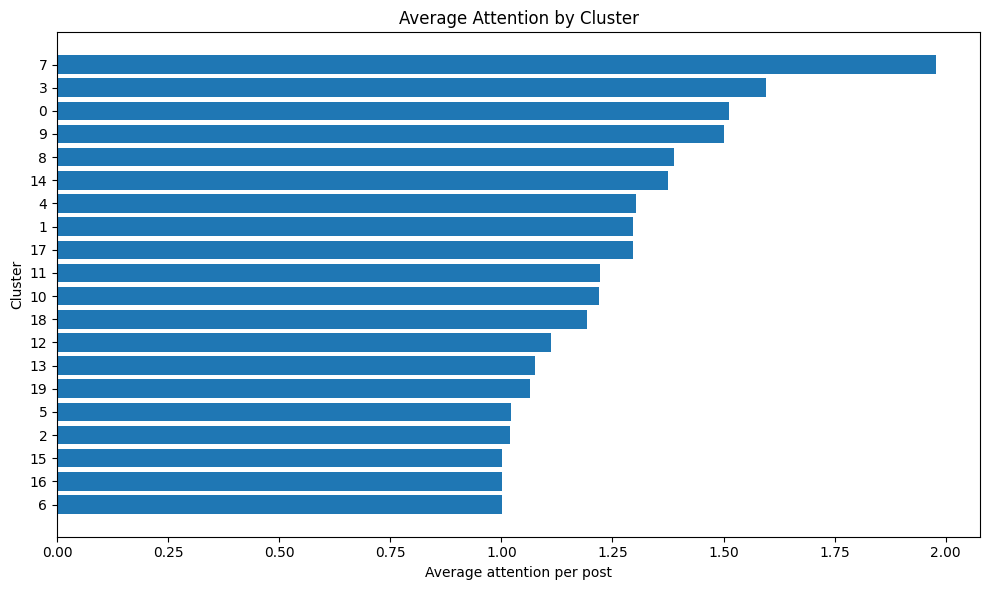

In [ ]:
plot_data = cluster_stats.sort_values(
    "AvgAttention",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index.astype(str),
    plot_data["AvgAttention"]
)

plt.xlabel("Average attention per post")
plt.ylabel("Cluster")
plt.title("Average Attention by Cluster")

plt.tight_layout()
plt.show()

In [ ]:
topic_names = {
    0: "Life & Lifestyle",
    1: "New York & Local News",
    2: "Motorsports & Live Racing",
    3: "News & General Discussion",
    4: "Google & Technology",
    5: "Music & Listening",
    6: "Online Videos",
    7: "General & Personal Updates",
    8: "Music & Music Videos",
    9: "General Web Content",
    10: "Making Money Online",
    11: "Free Downloads & Online Resources",
    12: "Home Products & Shopping",
    13: "Tips & Advice",
    14: "New Posts & Web Content",
    15: "Daily Blog Comments",
    16: "WordPress & Web Optimization",
    17: "Social Media & Marketing",
    18: "Digital Products & Electronics",
    19: "Business & Management"
}

entries_en["Topic"] = (
    entries_en["Cluster"]
    .map(topic_names)
)

In [ ]:
topic_stats = (
    entries_en
    .groupby("Topic")
    .agg(
        NumPosts=("EntryID", "count"),
        TotalAttention=("Attention", "sum"),
        AvgAttention=("Attention", "mean"),
        MedianAttention=("Attention", "median")
    )
    .sort_values(
        "AvgAttention",
        ascending=False
    )
)

display(topic_stats)

,NumPosts,TotalAttention,AvgAttention,MedianAttention
Topic,,,,
General & Personal Updates,14416,28518,1.978219,1.0
News & General Discussion,6580,10492,1.594529,1.0
Life & Lifestyle,4583,6935,1.513201,1.0
General Web Content,522394,783919,1.500628,1.0
Music & Music Videos,3964,5505,1.388749,1.0
New Posts & Web Content,17113,23530,1.374978,1.0
Google & Technology,10717,13953,1.301950,1.0
New York & Local News,2205,2856,1.295238,1.0
Social Media & Marketing,5593,7244,1.295190,1.0


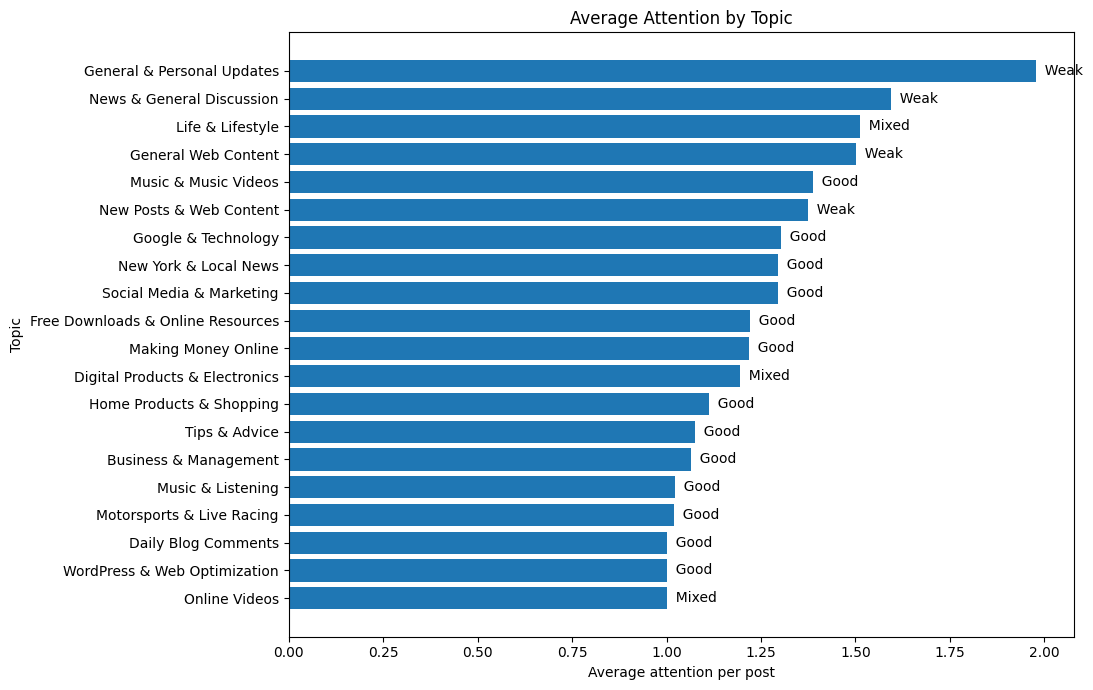

In [ ]:
topic_quality = {
    "Life & Lifestyle": "Mixed",
    "New York & Local News": "Good",
    "Motorsports & Live Racing": "Good",
    "News & General Discussion": "Weak",
    "Google & Technology": "Good",
    "Music & Listening": "Good",
    "Online Videos": "Mixed",
    "General & Personal Updates": "Weak",
    "Music & Music Videos": "Good",
    "General Web Content": "Weak",
    "Making Money Online": "Good",
    "Free Downloads & Online Resources": "Good",
    "Home Products & Shopping": "Good",
    "Tips & Advice": "Good",
    "New Posts & Web Content": "Weak",
    "Daily Blog Comments": "Good",
    "WordPress & Web Optimization": "Good",
    "Social Media & Marketing": "Good",
    "Digital Products & Electronics": "Mixed",
    "Business & Management": "Good"
}

plot_data = topic_stats.copy()

plot_data["Quality"] = plot_data.index.map(topic_quality)

plot_data = plot_data.sort_values(
    "AvgAttention",
    ascending=True
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    plot_data.index,
    plot_data["AvgAttention"]
)

plt.xlabel("Average attention per post")
plt.ylabel("Topic")
plt.title("Average Attention by Topic")

# Add quality next to each bar
for bar, quality in zip(bars, plot_data["Quality"]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {quality}",
        va="center"
    )

plt.tight_layout()
plt.show()

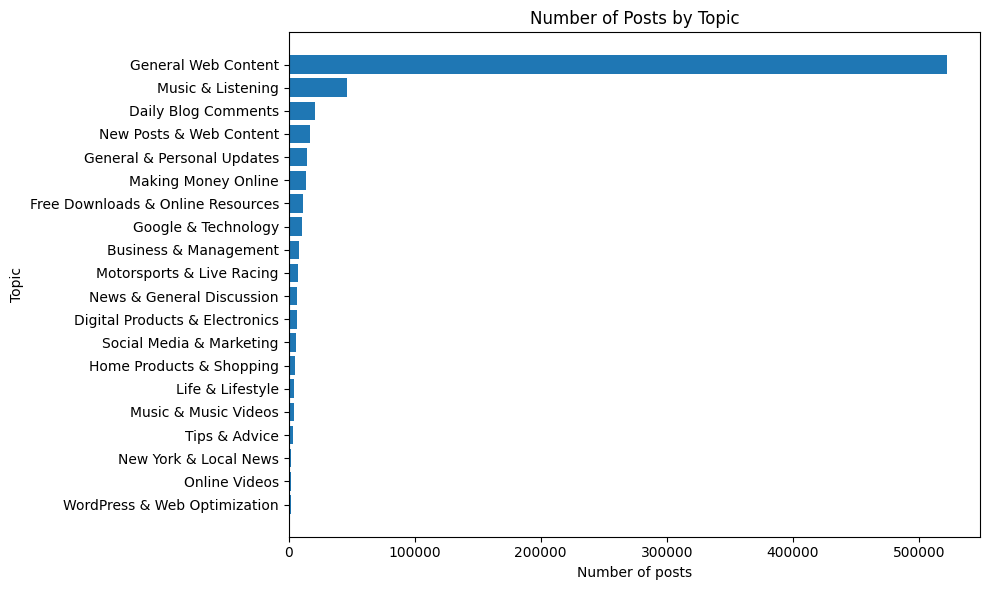

In [ ]:
plot_posts = topic_stats.sort_values(
    "NumPosts",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_posts.index,
    plot_posts["NumPosts"]
)

plt.xlabel("Number of posts")
plt.ylabel("Topic")
plt.title("Number of Posts by Topic")

plt.tight_layout()
plt.show()